# Kumbuka ML engine, final version (Project Deliverable 3): half-life regression

**Group:** BICS 3E  |  **Unit:** ICS 3202 Artificial Intelligence  |  **Dataset:** Duolingo half-life regression release (Settles & Meeder, 2016)
**Base model notebook (D2):** `HalfLifeRegression_Base.ipynb` in this same repo. This notebook repeats every step so it can be read on its own, then adds the full model comparison, the link to the app, and the exported model.

## The idea in one paragraph
Kumbuka is an Android app that tells a university student which topics to revise today. To rank topics it needs one guess per topic: **how likely am I to still remember this right now?** Memory fades over time, and it fades more slowly the more often you have successfully recalled something. Half-life regression turns that into a formula. Each topic has a *half-life*: the number of days until there is a 50/50 chance you have forgotten it. The model **learns** how the half-life grows with each right answer and shrinks with each wrong one, from 12.8 million real Duolingo reviews. Then the chance of remembering after *t* days is

> p = 2^(-t / h)   (after one half-life p = 0.5, after two p = 0.25, and so on)

Kumbuka suggests revising a topic once that chance falls below **90%**.

## Words used in this notebook
| Word | Plain meaning |
|---|---|
| *Model* | A formula whose numbers are learned from examples instead of picked by hand. |
| *Training / testing* | Learning the numbers from one group of learners, then checking the guesses on a different group the model never saw. |
| *Baseline* | A simple method we must beat for the model to be worth using. |
| *Regression* | A method that learns to predict a number (here, the half-life). |
| *MAE* | Mean absolute error: the average distance between the guess and the truth, on a 0 to 1 scale. Lower is better. |
| *AUC* | How well the guesses separate "remembered" from "forgot". 0.5 is a coin flip, 1.0 is perfect. Higher is better. |
| *Log-loss* | Like MAE but punishes guesses that were confident and wrong. Lower is better. |
| *Calibration* | Whether "80% likely" really comes true about 80% of the time. |

**H0 (null hypothesis):** the trained model guesses memory no better than the hand-written rule.
**H1:** the trained model guesses memory better.

## How this notebook follows the data mining process
| Stage | Step |
|---|---|
| Understand the problem | This section and "ML approach" |
| Understand the data | Step 1 (load) and Step 2 (explore, 4 observations) |
| Prepare the data | Step 2 (clean, duplicates, outliers, inputs) and Step 3 (split by learner) |
| Model | Steps 4 and 5 (baselines, half-life regression, tuning) |
| Evaluate | Steps 6 to 8 (all models side by side, repeat runs, second dataset) |
| Deploy | Steps 9 to 11 (choose the final model, how the app uses it, export) |
| Conclude | Step 12 |


## ML approach
- **Kind of learning:** *supervised regression*. Every example has a known answer (how much was recalled), and the model learns to predict it.
- **Final algorithm:** *half-life regression* (Settles & Meeder, 2016), fitted with *ridge regression* (ordinary regression with a small penalty that stops the learned numbers getting extreme).
- **What goes in:** days since the topic was last reviewed, and how many times it was answered right and wrong before.
- **What comes out:** a number from 0 to 1, the chance you still remember the topic right now.
- **Compared against (Step 6):** always guessing the average, the hand-written rule, logistic regression, and a random forest.
- **Why it can run inside a phone:** the final model is three numbers. No internet and no server are needed.


## Step 1: Load the dataset *(Person A)*
Same file as Deliverable 1 (Harvard Dataverse, `doi:10.7910/DVN/N8XJME/UEPJVH`). Each row is one learner practising one word in one session.
The file has 12 columns. We first get all of them, then load only the five we need to ensure colabs memory is sufficient.

In [1]:
import os
import numpy as np
import pandas as pd

FILE = os.environ.get("KUMBUKA_TRACES", "learning_traces.csv.gz")  # in Colab the file is downloaded below
if not os.path.exists(FILE):
    !wget -q -O {FILE} "https://dataverse.harvard.edu/api/access/datafile/:persistentId?persistentId=doi:10.7910/DVN/N8XJME/UEPJVH"

print("All columns in the file:", list(pd.read_csv(FILE, nrows=5).columns))

use = ["p_recall", "delta", "user_id", "history_seen", "history_correct"]
df = pd.read_csv(FILE, usecols=use, dtype={"user_id": "category"})
print(df.shape)
df.head()

All columns in the file: ['p_recall', 'timestamp', 'delta', 'user_id', 'learning_language', 'ui_language', 'lexeme_id', 'lexeme_string', 'history_seen', 'history_correct', 'session_seen', 'session_correct']


(12854226, 5)


,p_recall,delta,user_id,history_seen,history_correct
0,1.0,27649635,u:FO,6,4
1,0.5,27649635,u:FO,4,4
2,1.0,27649635,u:FO,5,4
3,0.5,27649635,u:FO,6,5
4,1.0,27649635,u:FO,4,4


**What the columns mean**
- `p_recall`: the share of this word's answers that were right *in this session* (0, 0.5 or 1 for most rows). This is what we try to predict.
- `delta`: seconds since the learner last practised this word.
- `history_seen` / `history_correct`: how many times the learner had seen the word before, and how many of those they got right.
- `user_id`: who the learner is. We use it to keep people from leaking between training and testing.

So we can see what wont be here : Theres nothing about what the word means. Duolingo's model never reads the content, only timing and past results. Kumbuka records exactly those things for a topic like "Learning Agents", which is why this model can transfer.

**Columns we leave out, and why**
- `timestamp`: when the session happened. Kumbuka works from *gaps* between reviews, which `delta` already gives us.
- `lexeme_id`, `lexeme_string`, `learning_language`, `ui_language`: they say *which word* and *which language*. A university topic has neither, and a model that leaned on them could not run inside the app.
- `session_seen`, `session_correct`: the counts inside the session being predicted. `p_recall` is built from them, so using them would be like peeking at the answer.

## Step 2: Explore and clean *(Person A)*
We go in this order: (a) check the whole file for missing values, impossible values and duplicates (steps 1, 3 and 5 of the course's data-cleaning recipe), (b) take a fixed random sample, (c) look at extreme values (step 6, outliers), (d) build the model inputs, (e) read four observations off the data, (f) summarise the final dataset.

**(a) Missing values, impossible values and duplicates, on all 12.8 million rows.** Each check prints how many rows break the rule. Rows that break one are dropped. Duplicates are removed with `drop_duplicates()`, as in the course notes ("remove all duplicate values"). Two rows can look identical without being the same event, because the word column is gone, so we report how many were removed and show that the result barely changes.

In [2]:
print("Missing values per column:")
print(df.isnull().sum())

rules = {
    "history_correct > history_seen (cannot get more right than you saw)": df["history_correct"] > df["history_seen"],
    "history_seen < 1 (no history, rule and model have nothing to use)":     df["history_seen"] < 1,
    "negative delta (time cannot run backwards)":                           df["delta"] < 0,
    "p_recall outside 0..1":                                                ~df["p_recall"].between(0, 1),
}
bad = pd.Series(False, index=df.index)
for name, mask in rules.items():
    print(f"{mask.sum():>10,}  rows: {name}")
    bad |= mask

rows_before = len(df)
df = df[~bad]
print(f"\nDropped {bad.sum():,} rows. Kept {len(df):,} of {rows_before:,}.")

# course step 1: scrub for duplicates
rows_after_bad = len(df)
n_dup = int(df.duplicated().sum())
print(f"Exact duplicate rows: {n_dup:,} ({n_dup / rows_after_bad:.1%} of the file)")
df = df.drop_duplicates()
print(f"After drop_duplicates(): {len(df):,} rows")

Missing values per column:
p_recall           0
delta              0
user_id            0
history_seen       0
history_correct    0
dtype: int64


         0  rows: history_correct > history_seen (cannot get more right than you saw)
         0  rows: history_seen < 1 (no history, rule and model have nothing to use)
         0  rows: negative delta (time cannot run backwards)
         0  rows: p_recall outside 0..1



Dropped 0 rows. Kept 12,854,226 of 12,854,226.


Exact duplicate rows: 1,717,691 (13.4% of the file)


After drop_duplicates(): 11,136,535 rows


**(b) Sample.** We use 1 million random rows with a fixed seed (`random_state=42`), so everyone gets identical results. The full file is more than the model needs: it has only a handful of numbers to learn.

**(c) Extreme values (outliers).** The course says to detect them with a boxplot, then drop or fix them if they come from errors. We draw the boxplots first, then decide.

Extreme values (99th percentile vs maximum):
  t_days           99th pct =     132.87   max =     460.17
  history_correct  99th pct =     235.00   max =   12877.00
  history_wrong    99th pct =      29.00   max =    2436.00


  t_days           13.8% of rows sit above the boxplot whisker (13.3)
  history_correct  11.1% of rows sit above the boxplot whisker (33.0)
  history_wrong    7.6% of rows sit above the boxplot whisker (5.0)


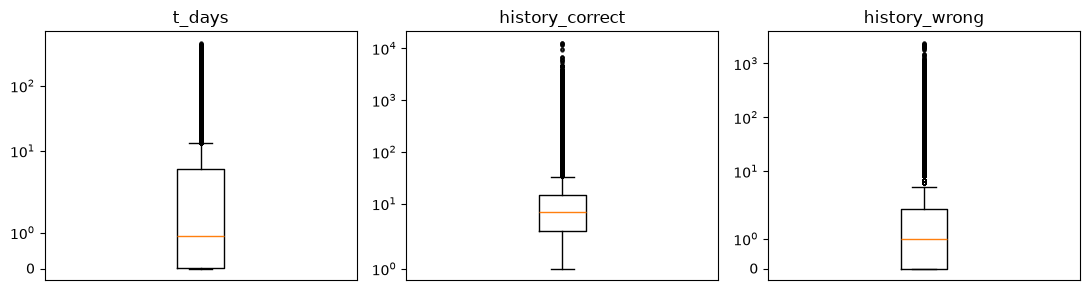

In [3]:
SEED = 42
H_MIN, H_MAX = 15 / (60 * 24), 274.0          # days: 15 minutes .. 274 days

d = df.sample(n=1_000_000, random_state=SEED).copy()
d["user_id"] = d["user_id"].astype(str)
d["t_days"] = d["delta"] / 86400.0
d["history_wrong"] = d["history_seen"] - d["history_correct"]

print("Extreme values (99th percentile vs maximum):")
for col in ["t_days", "history_correct", "history_wrong"]:
    print(f"  {col:16s} 99th pct = {d[col].quantile(0.99):10.2f}   max = {d[col].max():10.2f}")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
for a_, col in zip(ax, ["t_days", "history_correct", "history_wrong"]):
    a_.boxplot(d[col], showfliers=True, flierprops={"markersize": 2, "alpha": 0.3})
    a_.set_yscale("symlog"); a_.set_title(col); a_.set_xticks([])
    q1, q3 = d[col].quantile([0.25, 0.75]); upper = q3 + 1.5 * (q3 - q1)
    print(f"  {col:16s} {(d[col] > upper).mean():.1%} of rows sit above the boxplot whisker ({upper:.1f})")
plt.tight_layout(); plt.show()

**Decision on extreme values: keep them.** The boxplots show a long tail of points past the whiskers, which is what skewed counts look like. The course treats outliers as problems *caused by errors in data collection*. A learner who has seen a word 12,000 times, or one who returns after 460 days, is real behaviour, not a typing mistake, so we do not delete them or replace them with the mean. The model uses *square roots* of the counts, which tames big numbers, and the half-life target is capped (next cell), which tames big gaps.

**(d) Build the inputs and the target.** The half-life is how many days until you have a 50/50 chance of remembering. From a recall probability *p* after *t* days it is `h = -t / log2(p)`. A recall of exactly 0 or 1 gives an infinite or zero half-life, so, as in the Duolingo paper, we clip *p* to [0.0001, 0.9999] and *h* to between 15 minutes and 274 days.

In [4]:
d["recalled"] = (d["p_recall"] >= 0.5).astype(int)   # yes/no label, used for AUC

p_clip = d["p_recall"].clip(0.0001, 0.9999)
d["h_true"] = (-d["t_days"] / np.log2(p_clip)).clip(H_MIN, H_MAX)

print(d[["p_recall", "t_days", "history_correct", "history_wrong", "h_true"]].describe().round(3))
print("Share of rows recalled (>=0.5):", round(d["recalled"].mean(), 3))

          p_recall       t_days  history_correct  history_wrong       h_true
count  1000000.000  1000000.000      1000000.000    1000000.000  1000000.000
mean         0.883        8.616           21.760          2.996      154.610
std          0.286       26.255          122.206         28.447      124.583
min          0.000        0.000            1.000          0.000        0.010
25%          1.000        0.006            3.000          0.000       17.809
50%          1.000        0.917            7.000          1.000      274.000
75%          1.000        5.327           15.000          2.000      274.000
max          1.000      460.166        12877.000       2436.000      274.000
Share of rows recalled (>=0.5): 0.918


**(e) Four observations from the data.** Each cell below shows the evidence, and the line under it says what it means for the model.

Observation 1: 50.2% of the half-life targets sit exactly at the 274-day cap.
Half-life quantiles (days): {0.1: 0.5, 0.25: 17.8, 0.5: 274.0, 0.75: 274.0, 0.9: 274.0}


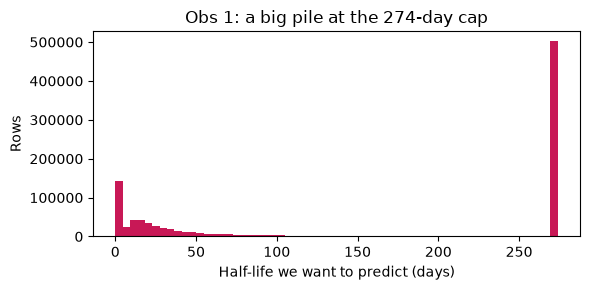

In [5]:
import matplotlib.pyplot as plt

capped = (d["h_true"] >= H_MAX).mean()
print(f"Observation 1: {capped:.1%} of the half-life targets sit exactly at the {H_MAX:.0f}-day cap.")
print("Half-life quantiles (days):", d["h_true"].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(1).to_dict())

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(d["h_true"], bins=60, color="#C81856")
ax.set_xlabel("Half-life we want to predict (days)"); ax.set_ylabel("Rows")
ax.set_title("Obs 1: a big pile at the 274-day cap")
plt.tight_layout(); plt.show()

**Observation 1: about half (50%) of the half-life targets are stuck at the 274-day ceiling.** The learner got the word right, so we cannot tell how long the memory would really last, only that it lasted at least that long. The model has to learn from a target that is "clipped" for most rows, which is one reason its scores are modest. *(The brief's EDA asks for critical observations: this is the one that changes how much we should trust the model.)*

Observation 2:
recalled
remembered    0.918
forgot        0.082
Name: proportion, dtype: float64


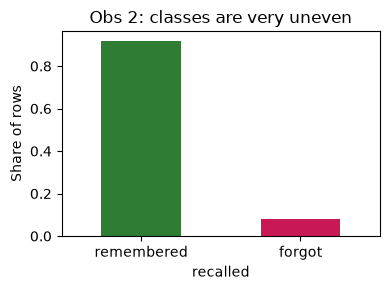

In [6]:
counts = d["recalled"].value_counts(normalize=True).rename({1: "remembered", 0: "forgot"})
print("Observation 2:")
print(counts.round(3))

fig, ax = plt.subplots(figsize=(4, 3))
counts.plot.bar(ax=ax, color=["#2E7D32", "#C81856"], rot=0)
ax.set_ylabel("Share of rows"); ax.set_title("Obs 2: classes are very uneven")
plt.tight_layout(); plt.show()

**Observation 2: about 92% of rows are "remembered".** The classes are very uneven. A lazy guesser that always says "remembered" is right 92% of the time, which is why we judge with MAE and AUC (and compare against "always guess the average") instead of plain accuracy.

Observation 3: days since last review
count    1000000.000
mean           8.616
std           26.255
min            0.000
25%            0.006
50%            0.917
75%            5.327
90%           20.140
99%          132.867
max          460.166
Name: t_days, dtype: float64
Share of reviews within 1 day of the last one: 52.5%


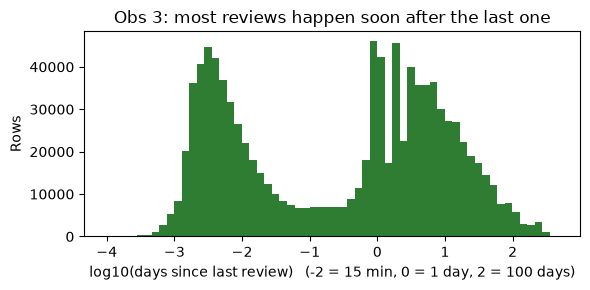

In [7]:
print("Observation 3: days since last review")
print(d["t_days"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(3))
print(f"Share of reviews within 1 day of the last one: {(d['t_days'] < 1).mean():.1%}")

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(np.log10(d["t_days"].clip(lower=1e-4)), bins=60, color="#2E7D32")
ax.set_xlabel("log10(days since last review)   (-2 = 15 min, 0 = 1 day, 2 = 100 days)")
ax.set_ylabel("Rows"); ax.set_title("Obs 3: most reviews happen soon after the last one")
plt.tight_layout(); plt.show()

**Observation 3: the typical (median) gap is about 0.9 days, and 52% of reviews happen within a day of the last.** Duolingo learners practise in bursts. A student revising for a university exam leaves *days or weeks* between reviews, so the model is being asked about longer gaps than most of what it learned from. This feeds the transfer limit in Step 10.

Observation 4: how much history learners have (before this review)
       history_seen  history_correct  history_wrong
count     1000000.0        1000000.0      1000000.0
mean           24.8             21.8            3.0
std           140.6            122.2           28.4
min             1.0              1.0            0.0
50%             7.0              7.0            1.0
90%            41.0             37.0            4.0
99%           269.0            235.0           29.0
max         13506.0          12877.0         2436.0



Learners in the sample: 88,134
Top 1% of learners supply 14.7% of the rows


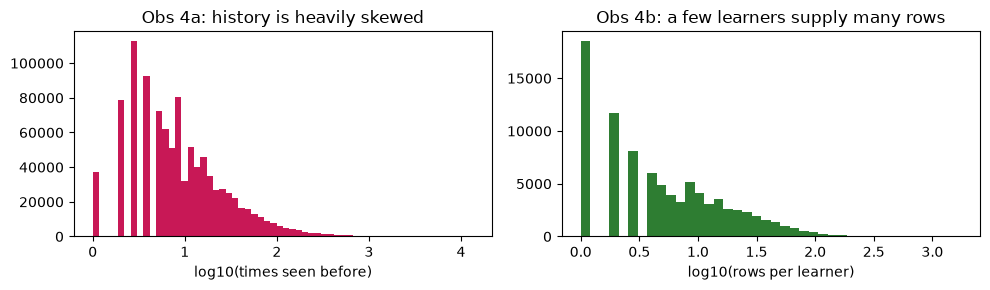

In [8]:
print("Observation 4: how much history learners have (before this review)")
print(d[["history_seen", "history_correct", "history_wrong"]].describe(percentiles=[0.5, 0.9, 0.99]).round(1))

per_user = d.groupby("user_id").size().sort_values(ascending=False)
print(f"\nLearners in the sample: {len(per_user):,}")
print(f"Top 1% of learners supply {per_user.head(max(1, len(per_user)//100)).sum() / len(d):.1%} of the rows")

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(np.log10(d["history_seen"].clip(lower=1)), bins=60, color="#C81856")
ax[0].set_xlabel("log10(times seen before)"); ax[0].set_title("Obs 4a: history is heavily skewed")
ax[1].hist(np.log10(per_user.values), bins=40, color="#2E7D32")
ax[1].set_xlabel("log10(rows per learner)"); ax[1].set_title("Obs 4b: a few learners supply many rows")
plt.tight_layout(); plt.show()

**Observation 4: history counts and rows-per-learner are both extremely right-skewed.** Most records have a short history, and a minority of heavy users have thousands (the top 1% of learners supply about 15% of the rows). That is why we use square roots of the counts, and why we split train and test by *learner* in Step 3: a few heavy users could otherwise dominate both piles.

**(f) The final dataset used for modelling**

In [9]:
print(f"Rows in the file:            {rows_before:,}")
print(f"After removing bad rows:     {len(df):,}")
print(f"Random sample used:          {len(d):,}  (seed {SEED})")
print("Inputs to the model:         t_days, history_correct, history_wrong")
print("Target (regression):         h_true, the half-life in days, from p_recall")
print("Label (for AUC only):        recalled = p_recall >= 0.5")
print("Missing values left:        ", int(d[["p_recall", "t_days", "history_correct", "history_wrong"]].isnull().sum().sum()))

Rows in the file:            12,854,226
After removing bad rows:     11,136,535
Random sample used:          1,000,000  (seed 42)
Inputs to the model:         t_days, history_correct, history_wrong
Target (regression):         h_true, the half-life in days, from p_recall
Label (for AUC only):        recalled = p_recall >= 0.5
Missing values left:         0


## Step 3: Split by learner, not by row *(Person A)*
If we split rows at random, the same person's history lands in both piles and the model looks smarter than it is. So we split **by learner**: 80% of learners to teach the model (*training*), 20% held back to test it (*testing*). The check below proves no learner appears in both.

In [10]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(gss.split(d, groups=d["user_id"]))
train, test = d.iloc[train_idx], d.iloc[test_idx]

overlap = set(train["user_id"]) & set(test["user_id"])
print("train rows:", len(train), "| test rows:", len(test))
print("learners in both piles:", len(overlap))
assert len(overlap) == 0

train rows: 798301 | test rows: 201699
learners in both piles: 0


## Step 4: The two baselines *(Person B)*
**(a) The hand-written rule.** A Python copy of the app's old `PlaceholderRecallPredictor` (the hand-set stand-in that the trained model has now replaced in the app): half-life = 4 days × (1 + rating ÷ 3), and recall = 0.5^(days ÷ half-life). In the app, *rating* is the student's last self-rating (0 to 3). Duolingo has no self-rating, so we stand in **past accuracy × 3** (a learner who got 100% right counts as rating 3). This substitution is a stated assumption, not a fact.

**Which "rule" is this?** It is that old `placeholder-v1` recall guess. It is *not* the weighted study-priority score in `DESIGN.md` section 4 (gap, staleness, urgency, avoidance), because that score ranks topics using exam dates and avoidance, which Duolingo data does not have, so it cannot be tested here. It is also a weak baseline: its 4-day half-life is far too short for this data, which is why it later scores worse than guessing the average. So "the model beats the rule" is a low bar, and "the model beats the average guess" (a small win) is the fairer test.

**(b) "Always guess the average."** The laziest possible guess. Any real method must beat it.

In [11]:
def rule_predict(frame):
    rating = 3.0 * frame["history_correct"] / frame["history_seen"]      # stand-in for the 0..3 self-rating
    half_life = 4.0 * (1.0 + rating / 3.0)                               # days
    return np.power(0.5, frame["t_days"] / half_life).clip(0, 1)

mean_recall = train["p_recall"].mean()
def average_predict(frame):
    return np.full(len(frame), mean_recall)

print("Average recall in training data:", round(mean_recall, 3))

Average recall in training data: 0.882


## Step 5: The model: half-life regression *(Person B)*
Duolingo's published idea: memory fades like `p = 2^(-t / h)`, and the half-life `h` itself depends on your history. We *learn* that dependence:

> log2(h) = a + b × √(1 + correct) + c × √(1 + wrong)

The square roots mean the 10th review helps less than the 1st (diminishing returns). We fit a, b, c with **ridge regression**: ordinary linear regression plus a penalty, *alpha*, that pulls the numbers towards zero so they cannot swing wildly. Too small an alpha and the model may chase noise (*overfit*); too large and it is forced to ignore the data (*underfit*).

**Choosing alpha properly.** We try six alphas and score each with **5-fold cross-validation grouped by learner**: split the *training* learners into 5 groups, train on 4, score on the 5th, rotate, and average. The test learners are not touched here. We pick the alpha with the lowest average MAE.

In [12]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold

def features(frame):
    return np.column_stack([np.sqrt(1 + frame["history_correct"]), np.sqrt(1 + frame["history_wrong"])])

def recall_from(frame, fitted):
    h = np.clip(np.power(2.0, fitted.predict(features(frame))), H_MIN, H_MAX)
    return np.power(2.0, -frame["t_days"].to_numpy() / h).clip(0, 1)

alphas = [0.01, 0.1, 1, 10, 100, 1000]
gkf = GroupKFold(n_splits=5)
sweep = []
for alpha in alphas:
    fold_mae = []
    for tr_i, va_i in gkf.split(train, groups=train["user_id"]):
        tr, va = train.iloc[tr_i], train.iloc[va_i]
        m = Ridge(alpha=alpha).fit(features(tr), np.log2(tr["h_true"]))
        fold_mae.append(np.abs(va["p_recall"].to_numpy() - recall_from(va, m)).mean())
    m_all = Ridge(alpha=alpha).fit(features(train), np.log2(train["h_true"]))
    sweep.append({"alpha": alpha, "CV MAE (mean)": np.mean(fold_mae), "CV MAE (spread)": np.std(fold_mae),
                  "w_correct": m_all.coef_[0], "w_wrong": m_all.coef_[1]})
sweep = pd.DataFrame(sweep).set_index("alpha")
print(sweep.round(5))

best_alpha = sweep["CV MAE (mean)"].idxmin()
print("\nBest alpha by cross-validation:", best_alpha)

         CV MAE (mean)  CV MAE (spread)  w_correct  w_wrong
alpha                                                      
0.01           0.17495          0.00156    0.09742 -0.60268
0.10           0.17495          0.00156    0.09742 -0.60268
1.00           0.17495          0.00156    0.09742 -0.60268
10.00          0.17495          0.00156    0.09742 -0.60267
100.00         0.17495          0.00156    0.09738 -0.60256
1000.00        0.17496          0.00156    0.09704 -0.60147

Best alpha by cross-validation: 0.01


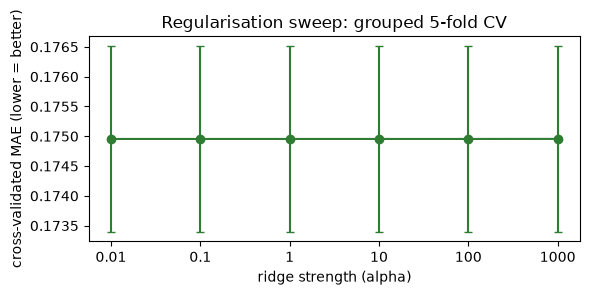

In [13]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.errorbar(range(len(alphas)), sweep["CV MAE (mean)"], yerr=sweep["CV MAE (spread)"], marker="o", color="#2E7D32", capsize=3)
ax.set_xticks(range(len(alphas))); ax.set_xticklabels(alphas)
ax.set_xlabel("ridge strength (alpha)"); ax.set_ylabel("cross-validated MAE (lower = better)")
ax.set_title("Regularisation sweep: grouped 5-fold CV")
plt.tight_layout(); plt.show()

**What the sweep shows (read it honestly).** The cross-validated MAE is about 0.1750 for every alpha from 0.01 to 1000, and the learned weights barely move. So alpha makes no real difference, and the model is **not** overfitting. That is expected here, because it has only *two* inputs and hundreds of thousands of training rows, so there is little room to chase noise. The code picks the lowest-MAE alpha (0.01), but the differences are far smaller than the spread between folds, so any of the small alphas would do. The ridge penalty is a safety measure we have demonstrated rather than a big lever.

In [14]:
model = Ridge(alpha=best_alpha)
model.fit(features(train), np.log2(train["h_true"]))
a, (b, c) = model.intercept_, model.coef_
print(f"alpha = {best_alpha}")
print(f"log2(h) = {a:.3f} + {b:.3f} * sqrt(1+correct) + {c:.3f} * sqrt(1+wrong)")

def half_life_predict(frame):
    return np.clip(np.power(2.0, model.predict(features(frame))), H_MIN, H_MAX)

def model_predict(frame):
    return np.power(2.0, -frame["t_days"] / half_life_predict(frame)).clip(0, 1)

alpha = 0.01
log2(h) = 5.938 + 0.097 * sqrt(1+correct) + -0.603 * sqrt(1+wrong)


**Reading the three numbers:** `b` says how much each past *correct* answer stretches the half-life; `c` says how much each past *wrong* answer changes it (usually it shrinks it). These are the model's learned weights. The hand-written rule had no such numbers learned from data.

## Step 6: Every model, side by side *(Person C)*
D2 promised to push more models through **the same pipeline**: same cleaned data, same learner-held-out split, same scores. Two extra models join the average guess, the rule and half-life regression:

- **Logistic regression:** a standard yes/no model. It predicts "remembered or not" directly from the same inputs. If it clearly beat half-life regression, the half-life idea would not be adding anything.
- **Random forest:** many small decision trees voting together. It can find patterns the half-life formula cannot, so it shows how much room is left above our model. We keep it small (50 trees, limited depth, trained on 200,000 rows) so it runs in a couple of minutes.

Scores: MAE against the real recall share, AUC and log-loss against the yes/no label (remembered = recall of at least 0.5).


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, roc_auc_score, log_loss

def wide_features(frame):
    # same information as half-life regression, plus the time gap as an input
    return np.column_stack([
        np.sqrt(1 + frame["history_correct"]),
        np.sqrt(1 + frame["history_wrong"]),
        np.log1p(frame["t_days"]),
    ])

logit = LogisticRegression(max_iter=1000).fit(wide_features(train), train["recalled"])
def logistic_predict(frame):
    return logit.predict_proba(wide_features(frame))[:, 1]

rf_rows = train.sample(n=min(200_000, len(train)), random_state=SEED)
forest = RandomForestRegressor(n_estimators=50, max_depth=12, min_samples_leaf=200, n_jobs=-1, random_state=SEED)
forest.fit(wide_features(rf_rows), rf_rows["p_recall"])
def forest_predict(frame):
    return forest.predict(wide_features(frame)).clip(0, 1)

all_methods = {
    "Average guess": average_predict(test),
    "Hand-written rule (baseline)": rule_predict(test).to_numpy(),
    "Half-life regression (final model)": model_predict(test).to_numpy(),
    "Logistic regression": logistic_predict(test),
    "Random forest": forest_predict(test),
}

def score_all(frame, preds):
    y_share, y_label = frame["p_recall"].to_numpy(), frame["recalled"].to_numpy()
    rows = []
    for name, p in preds.items():
        p = np.asarray(p, dtype=float)
        rows.append({
            "Method": name,
            "MAE (lower=better)": mean_absolute_error(y_share, p),
            "AUC (higher=better)": roc_auc_score(y_label, p) if np.std(p) > 0 else 0.5,
            "Log-loss (lower=better)": log_loss(y_label, np.clip(p, 1e-4, 1 - 1e-4)),
        })
    return pd.DataFrame(rows).set_index("Method")

methods = {k: all_methods[k] for k in ["Hand-written rule (baseline)", "Half-life regression (final model)"]}
methods["Half-life regression (model)"] = methods["Half-life regression (final model)"]  # name used by Step 7
comparison = score_all(test, all_methods)
comparison.round(4)


,MAE (lower=better),AUC (higher=better),Log-loss (lower=better)
Method,,,
Average guess,0.1907,0.5000,0.2872
Hand-written rule (baseline),0.2778,0.5381,0.8883
Half-life regression (final model),0.1714,0.5445,0.5118
Logistic regression,0.1653,0.5901,0.2757
Random forest,0.1854,0.5925,0.2816


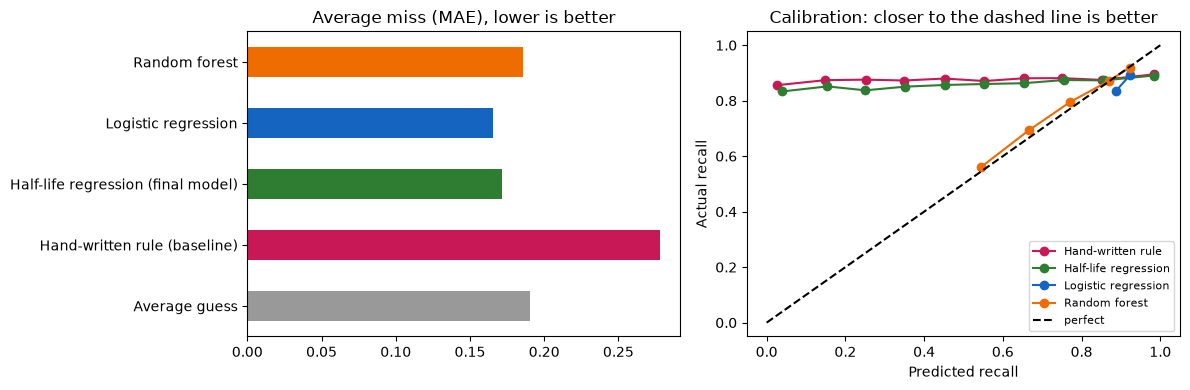

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
colours = ["#999999", "#C81856", "#2E7D32", "#1565C0", "#EF6C00"]
comparison["MAE (lower=better)"].plot.barh(ax=ax[0], color=colours)
ax[0].set_title("Average miss (MAE), lower is better"); ax[0].set_ylabel("")

bins = np.linspace(0, 1, 11)
y_share = test["p_recall"].to_numpy()
for (name, pred), colour in zip(all_methods.items(), colours):
    if name == "Average guess":
        continue
    which = np.digitize(pred, bins[1:-1]); xs, ys = [], []
    for k in range(10):
        m = which == k
        if m.sum() > 200:
            xs.append(pred[m].mean()); ys.append(y_share[m].mean())
    ax[1].plot(xs, ys, marker="o", label=name.split(" (")[0], color=colour)
ax[1].plot([0, 1], [0, 1], "--", color="black", label="perfect")
ax[1].set_xlabel("Predicted recall"); ax[1].set_ylabel("Actual recall")
ax[1].set_title("Calibration: closer to the dashed line is better"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


**How to read this (honestly).**
- Every learned model beats the hand-written rule by a wide margin, and the rule is worse than just guessing the average (MAE 0.278 vs 0.191).
- **Logistic regression is the best model on all three scores here**: MAE 0.165 vs 0.171 for half-life regression, AUC 0.590 vs 0.545, log-loss 0.276 vs 0.512. The random forest is close to it on AUC and log-loss.
- **Half-life regression's log-loss (0.512) is worse than the plain average guess (0.287).** It is *overconfident*: when someone forgot, it had often said they would almost certainly remember. The calibration chart shows the same thing. The Anki check in Step 8 found the same weakness.
- So our model is a big step up from the hand-written rule, but it is not the most accurate learned model. Step 9 explains the trade-off and what we do about it.


## Step 7: Is the gap real or luck? *(Person C)*
**(a) Re-sample the test rows.**
A single score could be a fluke. We re-score on 20 random resamples of the test rows and check that the model's error is lower in every one (a simple *bootstrap*: re-shuffle, re-measure, count).

In [17]:
rng = np.random.default_rng(SEED)
y = test["p_recall"].to_numpy()
rule_p, model_p = methods["Hand-written rule (baseline)"], methods["Half-life regression (model)"]

wins, diffs = 0, []
for _ in range(20):
    i = rng.integers(0, len(y), len(y))
    diff = np.abs(y[i] - rule_p[i]).mean() - np.abs(y[i] - model_p[i]).mean()   # >0 means model better
    diffs.append(diff); wins += diff > 0
print(f"Model beat the rule in {wins}/20 resamples. Average MAE improvement: {np.mean(diffs):.4f}")

Model beat the rule in 20/20 resamples. Average MAE improvement: 0.1063


**(b) Repeat the whole split with five different seeds.** One lucky split of learners could flatter a model. We redo Steps 3 to 6 (new split, refit, rescore) five times and report the average and the spread (standard deviation, *sd*). The random forest is left out here only to save time.


In [18]:
repeat_rows = []
for seed in [1, 2, 3, 4, 5]:
    tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed).split(d, groups=d["user_id"]))
    tr, te = d.iloc[tr_i], d.iloc[te_i]
    hlr = Ridge(alpha=best_alpha).fit(features(tr), np.log2(tr["h_true"]))
    lg = LogisticRegression(max_iter=1000).fit(wide_features(tr), tr["recalled"])
    preds = {
        "Average guess": np.full(len(te), tr["p_recall"].mean()),
        "Hand-written rule (baseline)": rule_predict(te).to_numpy(),
        "Half-life regression (final model)": recall_from(te, hlr),
        "Logistic regression": lg.predict_proba(wide_features(te))[:, 1],
    }
    s = score_all(te, preds).reset_index(); s["seed"] = seed
    repeat_rows.append(s)
repeats = pd.concat(repeat_rows)
summary = repeats.groupby("Method")[["MAE (lower=better)", "AUC (higher=better)", "Log-loss (lower=better)"]].agg(["mean", "std"])
summary.round(4)


MAE (lower=better)          \
                                                 mean     std   
Method                                                          
Average guess                                  0.1919  0.0010   
Half-life regression (final model)             0.1745  0.0016   
Hand-written rule (baseline)                   0.2819  0.0020   
Logistic regression                            0.1666  0.0011   

                                   AUC (higher=better)          \
                                                  mean     std   
Method                                                           
Average guess                                   0.5000  0.0000   
Half-life regression (final model)              0.5478  0.0057   
Hand-written rule (baseline)                    0.5384  0.0037   
Logistic regression                             0.5975  0.0088   

                                   Log-loss (lower=better)          
                                                      mean     std  
Method                                                              
Average guess                                       0.2906  0.0031  
Half-life regression (final model)                  0.5161  0.0065  
Hand-written rule (baseline)                        0.9034  0.0088  
Logistic regression                                 0.2794  0.0032

**Reading it.** If the spread (sd) is much smaller than the gap between two methods, the ranking is not luck. The rule-versus-model gap is many times bigger than the spread in every run.


## Step 8: A second dataset: Anki review logs *(Person C)*
To check the ranking does not depend on Duolingo, we repeated the rule vs half-life regression vs logistic regression comparison on **Anki** flashcard review logs (`open-spaced-repetition/anki-revlogs-10k` on Hugging Face, 40 learners, about 1.04 million reviews, split by learner: 28 train, 12 test). The script is `anki_experiment.py` in this repo. Anki has no recall share, only remembered yes/no, so MAE here is not directly comparable to Duolingo's.

| Anki test set (12 held-out learners, 392,210 reviews) | MAE | AUC | Log-loss |
|---|---|---|---|
| Always guess the average | 0.320 | 0.500 | 0.562 |
| Hand-written rule | 0.487 | 0.484 | 1.527 |
| Half-life regression | 0.273 | 0.604 | 0.783 |
| Logistic regression | 0.312 | 0.702 | 0.499 |

**What it tells us.** Half-life regression beat the hand-written rule again, on 12 of 12 test learners and in 20 of 20 re-samples. But it was **overconfident**: it often said about 95% where the real rate was about 79%, which is why its log-loss is worse than the plain average. Logistic regression had the best AUC and log-loss there. So "learned beats hand-written" holds on two datasets; "half-life regression is the best learned model" does not. We use this result directly in Step 10: because the model tends to be too optimistic, Kumbuka asks for revision while it still predicts 90%, not 50%.


## Step 9: Choosing the final model *(everyone)*
Steps 6 to 8 show logistic regression gets better *average* scores than half-life regression on both datasets. So why not use it? The table below the reasons answers that: we asked both models about the same two topics, a strong one (3 right, 0 wrong) and a weak one (0 right, 3 wrong), at different times since the last review.

**What the table shows**
- **Logistic regression hardly uses time.** The strong topic only drops from 93% to 89% over 90 days. Its weight on time is small (about -0.10). It scores well on average mainly by learning that most reviews are remembered (Observation 2), not by learning how memory fades.
- **That makes it a poor scheduler.** The weak topic starts at 88%, *below* the 90% target, right after revising. So it would be due again immediately, every time, however often the student revises it. The strong topic would wait 29 days.
- **Half-life regression gives a clean, believable story.** Every topic is at 100% straight after revising and halves every half-life. The weak topic comes back after about 4.5 days and the strong one after about 7.5. Revising always helps, waiting always lowers the chance, and wrong answers bring a topic back sooner.

**So we choose half-life regression**, because Kumbuka's job is to decide *when* to revise:
1. **The explanation has one idea in it.** "Memory has a half-life. Wrong answers shorten it, right answers lengthen it a little, and the chance halves every half-life." The app's *Why this?* screen and the session summary show exactly these numbers (Step 10).
2. **Its behaviour always makes sense to a student**, as the table shows, while logistic regression's does not.
3. **It is tiny.** Three numbers in the app: no internet, no server, almost no energy (*sustainable AI*).
4. **It is the published method the project was designed around** (Settles & Meeder, 2016).

**What we give up, and how we handle it.** Half-life regression's average scores are a little worse, and it is overconfident (Steps 6 and 8). The app handles the overconfidence by suggesting revision while the model still predicts **90%** (Step 10) instead of waiting for 50%. **The next improvement** would be to retrain on Anki review logs, where the four buttons (Again, Hard, Good, Easy) match Kumbuka's Blank, Shaky, OK and Solid more closely than Duolingo's right/wrong.


In [19]:
# How would each model explain the same two topics to a student?
TARGET_CHECK = 0.90
def hlr_explain(right, wrong, days):
    h = float(np.clip(2 ** (model.intercept_ + model.coef_[0] * np.sqrt(1 + right) + model.coef_[1] * np.sqrt(1 + wrong)), H_MIN, H_MAX))
    return 2 ** (-days / h), h

def logistic_explain(right, wrong, days):
    x = np.array([[np.sqrt(1 + right), np.sqrt(1 + wrong), np.log1p(days)]])
    return float(logit.predict_proba(x)[0, 1])

def first_day_below(fn, target=TARGET_CHECK):
    for t in np.arange(0, 366, 0.5):
        if fn(t) < target:
            return float(t)
    return None

print("Logistic regression's learned weights:")
for name, w in zip(["sqrt(1+right)", "sqrt(1+wrong)", "log(1+days)"], logit.coef_[0]):
    print(f"  {name:14s} {w:+.3f}")
print(f"  intercept      {logit.intercept_[0]:+.3f}")

rows = []
for label, (r, w) in [("Strong topic: 3 right, 0 wrong", (3, 0)), ("Weak topic: 0 right, 3 wrong", (0, 3))]:
    _, h = hlr_explain(r, w, 0)
    for t in [0, 1, 7, 30, 90]:
        rows.append({"topic": label, "days since review": t,
                     "half-life regression p": round(hlr_explain(r, w, t)[0], 3),
                     "logistic regression p": round(logistic_explain(r, w, t), 3)})
    rows.append({"topic": label, "days since review": "due after (p < 90%)",
                 "half-life regression p": first_day_below(lambda t: hlr_explain(r, w, t)[0]),
                 "logistic regression p": first_day_below(lambda t: logistic_explain(r, w, t))})
pd.DataFrame(rows)


Logistic regression's learned weights:
  sqrt(1+right)  +0.152
  sqrt(1+wrong)  -0.379
  log(1+days)    -0.097
  intercept      +2.602


,topic,days since review,half-life regression p,logistic regression p
0,"Strong topic: 3 right, 0 wrong",0,1.000,0.926
1,"Strong topic: 3 right, 0 wrong",1,0.985,0.921
2,"Strong topic: 3 right, 0 wrong",7,0.900,0.911
3,"Strong topic: 3 right, 0 wrong",30,0.638,0.900
4,"Strong topic: 3 right, 0 wrong",90,0.259,0.890
5,"Strong topic: 3 right, 0 wrong",due after (p < 90%),7.500,29.000
6,"Weak topic: 0 right, 3 wrong",0,1.000,0.880
7,"Weak topic: 0 right, 3 wrong",1,0.976,0.873
8,"Weak topic: 0 right, 3 wrong",7,0.843,0.857
9,"Weak topic: 0 right, 3 wrong",30,0.481,0.841


## Step 10: How the app uses the model, including bad inputs *(Person B)*
Kumbuka has no right/wrong answers like Duolingo. Before revising a topic, the student rates how well they could recall it: **Blank, Shaky, OK or Solid**. The app turns those ratings into the model's inputs:

| App rating before revising | Counts as |
|---|---|
| OK or Solid | a **right** answer (the student could recall it) |
| Blank or Shaky | a **wrong** answer |

- *t* = days since the topic was last reviewed (from the app's session log).
- Only finished, rated reviews count. A deferred (skipped) session does not.
- **No rated review yet** ("cold start"): the model has no last-review time to work from, so the app uses the baseline formula for that topic and says so.
- **Due rule:** suggest revising once the predicted chance of remembering falls below **90%**. That happens after h × log2(1/0.9), which is about **0.152 × the half-life**.

The function below is the same logic as the Kotlin code in the app (`HlrRecallPredictor`). It checks its inputs the way the app does.


In [20]:
A, W_RIGHT, W_WRONG = float(model.intercept_), float(model.coef_[0]), float(model.coef_[1])
TARGET = 0.90
VALID = {"Blank": 0, "Shaky": 0, "OK": 1, "Solid": 1}   # 1 = counts as right

def kumbuka_predict(ratings, days_since):
    """ratings: list of before-revision self-ratings; days_since: days since the last of them."""
    if not isinstance(ratings, (list, tuple)):
        raise ValueError("ratings must be a list")
    bad = [r for r in ratings if r not in VALID]
    if bad:
        raise ValueError(f"unknown rating(s) {bad}; expected Blank, Shaky, OK or Solid")
    if len(ratings) == 0:
        return {"source": "baseline (cold start: no rated review yet)"}
    try:
        t = float(days_since)
    except (TypeError, ValueError):
        raise ValueError("days_since must be a number")
    note = ""
    if np.isnan(t) or t < 0:
        note = "negative or missing gap treated as 0 (phone clock moved back)"
        t = 0.0
    right = sum(VALID[r] for r in ratings); wrong = len(ratings) - right
    h = float(np.clip(2 ** (A + W_RIGHT * np.sqrt(1 + right) + W_WRONG * np.sqrt(1 + wrong)), H_MIN, H_MAX))
    p = 2 ** (-t / h)
    return {"source": "trained model", "right": right, "wrong": wrong, "half_life_days": round(h, 1),
            "days_since": t, "p_remember": round(p, 3), "due": p < TARGET,
            "due_after_days": round(h * np.log2(1 / TARGET), 1), "note": note}

examples = [
    ("Strong topic, reviewed 3 days ago", ["OK", "Solid", "Solid"], 3),
    ("Strong topic, reviewed 10 days ago", ["OK", "Solid", "Solid"], 10),
    ("Weak topic, reviewed 3 days ago", ["Blank", "Shaky", "Shaky"], 3),
    ("Weak topic, reviewed 10 days ago", ["Blank", "Shaky", "Shaky"], 10),
    ("One review, 6 days ago", ["Shaky"], 6),
    ("Never reviewed (cold start)", [], 5),
    ("Invalid: unknown rating", ["Great"], 2),
    ("Invalid: days is text", ["OK"], "yesterday"),
    ("Edge: clock moved back", ["OK"], -2),
]
rows = []
for label, ratings, days in examples:
    try:
        out = kumbuka_predict(ratings, days)
    except ValueError as e:
        out = {"source": f"rejected: {e}"}
    rows.append({"case": label, "ratings": ratings, "days": days, **out})
pd.DataFrame(rows).fillna("")


,case,ratings,days,source,right,wrong,half_life_days,days_since,p_remember,due,due_after_days,note
0,"Strong topic, reviewed 3 days ago","[OK, Solid, Solid]",3,trained model,3.0,0.0,46.2,3.0,0.956,False,7.0,
1,"Strong topic, reviewed 10 days ago","[OK, Solid, Solid]",10,trained model,3.0,0.0,46.2,10.0,0.861,True,7.0,
2,"Weak topic, reviewed 3 days ago","[Blank, Shaky, Shaky]",3,trained model,0.0,3.0,28.5,3.0,0.93,False,4.3,
3,"Weak topic, reviewed 10 days ago","[Blank, Shaky, Shaky]",10,trained model,0.0,3.0,28.5,10.0,0.784,True,4.3,
4,"One review, 6 days ago",[Shaky],6,trained model,0.0,1.0,36.3,6.0,0.892,True,5.5,
5,Never reviewed (cold start),[],5,baseline (cold start: no rated review yet),,,,,,,,
6,Invalid: unknown rating,[Great],2,rejected: unknown rating(s) ['Great']; expecte...,,,,,,,,
7,Invalid: days is text,[OK],yesterday,rejected: days_since must be a number,,,,,,,,
8,Edge: clock moved back,[OK],-2,trained model,1.0,0.0,44.4,0.0,1.0,False,6.8,negative or missing gap treated as 0 (phone cl...


**Reading the table.** The same gap gives a lower chance of remembering for a weak topic than a strong one, and a longer gap lowers it further, so the ranking changes the way it should. Bad inputs never crash the engine: an unknown rating or a non-number is rejected with a message, a negative gap is treated as zero, and a topic with no history is handed to the baseline formula. In the app the ratings come from four buttons, so an unknown rating cannot actually be entered; the check is there for safety.


In [21]:
grid = []
for right, wrong in [(0, 1), (1, 0), (1, 2), (3, 0), (2, 3), (5, 1), (0, 4)]:
    h = float(np.clip(2 ** (A + W_RIGHT * np.sqrt(1 + right) + W_WRONG * np.sqrt(1 + wrong)), H_MIN, H_MAX))
    grid.append({"right": right, "wrong": wrong, "half-life (days)": round(h, 1),
                 "due after (days, p<90%)": round(h * np.log2(1 / TARGET), 1),
                 "p after 7 days": round(2 ** (-7 / h), 3), "p after 14 days": round(2 ** (-14 / h), 3)})
due_table = pd.DataFrame(grid)
due_table


,right,wrong,half-life (days),"due after (days, p<90%)",p after 7 days,p after 14 days
0,0,1,36.3,5.5,0.875,0.766
1,1,0,44.4,6.8,0.897,0.804
2,1,2,32.7,5.0,0.862,0.743
3,3,0,46.2,7.0,0.900,0.811
4,2,3,29.9,4.5,0.850,0.723
5,5,1,40.1,6.1,0.886,0.785
6,0,4,25.8,3.9,0.828,0.686


**What a student would see.** Wrong answers shorten the half-life far more than right answers lengthen it (the learned weights in Step 5 say the same: the "wrong" weight is several times bigger). So a topic you keep rating Blank or Shaky comes back within days, while a topic you keep getting right waits longer. Because Duolingo learners practise in short bursts (Observation 3), the learned effect of right answers is weak; real student data from the Research Methodology study is what would sharpen it.


## Step 11: Save the model for the app *(Person C)*
The whole model is three numbers plus two limits. We save them, the 90% target, the rating mapping, and a few test cases to `kumbuka_hlr_v2.json`. The app's unit test checks that the Kotlin code gives the same answers as this notebook for those test cases, so the phone and the notebook cannot drift apart.


In [22]:
import json

test_cases = []
for right, wrong, days in [(0, 1, 0.0), (1, 0, 3.0), (2, 1, 7.0), (0, 3, 14.0), (5, 2, 30.0), (3, 0, 2.5)]:
    h = float(np.clip(2 ** (A + W_RIGHT * np.sqrt(1 + right) + W_WRONG * np.sqrt(1 + wrong)), H_MIN, H_MAX))
    test_cases.append({"right": right, "wrong": wrong, "days": days, "half_life_days": h, "p": 2 ** (-days / h)})

export = {
    "version": "hlr-v2",
    "formula": "log2(h_days) = intercept + w_correct*sqrt(1+correct) + w_wrong*sqrt(1+wrong); p = 2^(-t_days/h_days)",
    "intercept": A, "w_correct": W_RIGHT, "w_wrong": W_WRONG,
    "h_min_days": H_MIN, "h_max_days": H_MAX, "ridge_alpha": float(best_alpha),
    "target_recall": TARGET,
    "rating_mapping": {"right": ["OK", "Solid"], "wrong": ["Blank", "Shaky"]},
    "trained_on": "Duolingo half-life regression release, duplicates removed, 1M-row sample, learner-held-out split, seed 42",
    "test_cases": test_cases,
}
with open("kumbuka_hlr_v2.json", "w") as f:
    json.dump(export, f, indent=2)

final_results = {
    "comparison": comparison.round(4).reset_index().to_dict(orient="records"),
    "repeats": {m: {k: float(v) for k, v in row.items()} for m, row in
                summary.round(4).set_axis([f"{a} {b}" for a, b in summary.columns], axis=1).iterrows()},
    "bootstrap_wins": int(wins),
}
with open("final_results.json", "w") as f:
    json.dump(final_results, f, indent=2)
print(json.dumps({k: v for k, v in export.items() if k != "test_cases"}, indent=2))


{
  "version": "hlr-v2",
  "formula": "log2(h_days) = intercept + w_correct*sqrt(1+correct) + w_wrong*sqrt(1+wrong); p = 2^(-t_days/h_days)",
  "intercept": 5.938361999953164,
  "w_correct": 0.09741891008618403,
  "w_wrong": -0.602679947698708,
  "h_min_days": 0.010416666666666666,
  "h_max_days": 274.0,
  "ridge_alpha": 0.01,
  "target_recall": 0.9,
  "rating_mapping": {
    "right": [
      "OK",
      "Solid"
    ],
    "wrong": [
      "Blank",
      "Shaky"
    ]
  },
  "trained_on": "Duolingo half-life regression release, duplicates removed, 1M-row sample, learner-held-out split, seed 42"
}


## Step 12: Conclusion and honest limits *(Person C)*
**Result against H0.** On learners the model never saw, half-life regression's average error (MAE) was 0.171 against 0.278 for the hand-written rule, it was lower in 20 of 20 re-samples of the test rows and in all 5 repeated splits, and its AUC was slightly higher (0.545 vs 0.538). So we **reject H0**: the trained model guesses memory better than the hand-written rule. Two honest qualifications: the win over the plain average guess is small (0.171 vs 0.191), and logistic regression beat our model on every score, so a trained model clearly beats a hand-picked one, but half-life regression is not the best trained model we tested. *(Draft written for the group: reword it in your own words before submitting.)*

**What this does and does not show.**
1. **Duolingo marks answers automatically; Kumbuka relies on the student rating themselves.** A model trained on objective right/wrong may behave differently on honesty-dependent ratings. This is the central threat to validity.
2. **A Duolingo word is reviewed dozens of times; a university topic may be reviewed 5 to 8 times a semester.** The model learned from rich histories and will see thin ones in the app.
3. **Cold start.** With no rated review there is nothing to predict from, so the baseline formula covers a topic until its first rated review.
4. **The rule's rating was a stand-in** (past accuracy × 3), because Duolingo has no self-rating.
5. **About half of the half-life targets are clipped at the 274-day cap**, and Duolingo reviews are bunched close together. Both limit what the model learns about long gaps, which is what university revision needs.
6. **The model is over-optimistic on a second dataset (Anki)**, which is why the app revises at a 90% target.
7. **This compares guesses about memory, not exam results.** Whether better guesses help students score higher is the separate Research Methodology study, which compares two matched sets of topics per student.

**Sustainable AI.** The final model is three numbers that run on the phone: no server, no network calls, and almost no energy once trained.

**Reference.** Settles, B., & Meeder, B. (2016). A trainable spaced repetition model for language learning. *Proceedings of ACL 2016*, 1848-1858.
